In [1]:
from pathlib import Path
import subprocess

if not Path("GoldNet").exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/zobeirraisi/GoldNet.git"
    ], check=True)

data_dir = Path("GoldNet/gold")

for label in ["real", "fake"]:
    folder = data_dir / label
    images = list(folder.glob("*.jpg"))
    print(label, ":", len(images))

print("Dataset downloaded!")


real : 1041
fake : 1083
Dataset downloaded!


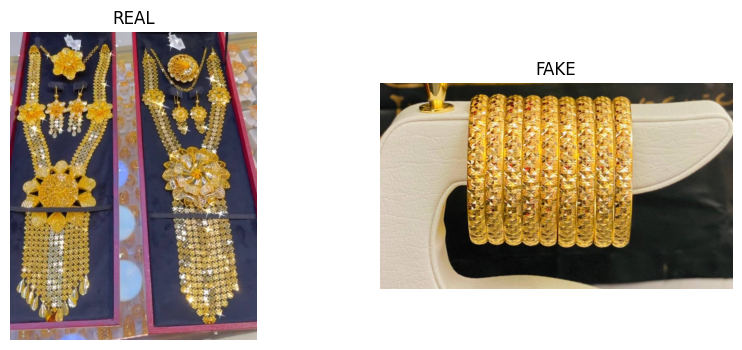

In [2]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, label in zip(axes, ["real", "fake"]):
    images = list((data_dir / label).glob("*.jpg"))

    if images:
        img = Image.open(images[0])
        ax.imshow(img)
        ax.set_title(label.upper())
    else:
        ax.set_title("No images found")

    ax.axis("off")

plt.show()


In [3]:
from pathlib import Path
from PIL import Image

extensions = {".jpg", ".jpeg", ".png", ".webp"}
data = []

for label in ["real", "fake"]:
    folder = data_dir / label
    for file in folder.rglob("*"):
        if file.suffix.lower() in extensions:
            try:
                with Image.open(file) as img:
                    img.verify()
                data.append((str(file), label))
            except Exception:
                print("Broken image:", file)

print("Valid images:", len(data))
print("Real:", sum(label == "real" for _, label in data))
print("Fake:", sum(label == "fake" for _, label in data))


Valid images: 2127
Real: 1044
Fake: 1083


In [4]:
from sklearn.model_selection import train_test_split

paths = [item[0] for item in data]
labels = [item[1] for item in data]

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths, labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))


Train: 1488
Validation: 319
Test: 320


In [5]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

class GoldDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        image = self.transform(image)
        label = 1 if self.labels[index] == "fake" else 0
        return image, label

normal_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

augmented_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

train_d0 = GoldDataset(train_paths, train_labels, normal_transform)
train_d1 = GoldDataset(train_paths, train_labels, augmented_transform)

val_dataset = GoldDataset(val_paths, val_labels, normal_transform)
test_dataset = GoldDataset(test_paths, test_labels, normal_transform)

train_loader_d0 = DataLoader(train_d0, batch_size=32, shuffle=True)
train_loader_d1 = DataLoader(train_d1, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

print("D0:", len(train_d0))
print("D1:", len(train_d1))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Using: cuda
D0: 1488
D1: 1488
Validation: 319
Test: 320


In [6]:
import torch
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import f1_score
import copy
import random
import numpy as np

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def create_model():
    model = resnet18(weights=ResNet18_Weights.DEFAULT)

    for parameter in model.parameters():
        parameter.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, 2)
    return model.to(device)

def evaluate(model, loader):
    model.eval()
    predictions = []
    actual = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            predictions.extend(outputs.argmax(1).cpu().tolist())
            actual.extend(labels.tolist())

    return f1_score(actual, predictions, zero_division=0)

def train_model(loader, epochs=5):
    set_seed()
    model = create_model()
    optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()

    best_f1 = -1
    best_weights = None

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        val_f1 = evaluate(model, val_loader)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {total_loss/len(loader):.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    return model

print("Training D0...")
model_d0 = train_model(train_loader_d0)
torch.save(model_d0.state_dict(), "model_d0.pth")
print("D0 training completed!")


Training D0...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


Epoch 1/5 | Loss: 0.6574 | Val F1: 0.6760
Epoch 2/5 | Loss: 0.5376 | Val F1: 0.6986
Epoch 3/5 | Loss: 0.4929 | Val F1: 0.7158
Epoch 4/5 | Loss: 0.4858 | Val F1: 0.8061
Epoch 5/5 | Loss: 0.4550 | Val F1: 0.7595
D0 training completed!


In [7]:
print("Training D1 with augmentation...")

model_d1 = train_model(train_loader_d1, epochs=5)

torch.save(model_d1.state_dict(), "model_d1.pth")

print("D1 training completed!")


Training D1 with augmentation...
Epoch 1/5 | Loss: 0.6645 | Val F1: 0.6204
Epoch 2/5 | Loss: 0.5653 | Val F1: 0.6997
Epoch 3/5 | Loss: 0.5104 | Val F1: 0.7670
Epoch 4/5 | Loss: 0.4907 | Val F1: 0.7859
Epoch 5/5 | Loss: 0.4882 | Val F1: 0.7966
D1 training completed!


FINAL TEST RESULTS:
           D0 Original  D1 Augmented
Accuracy        0.7188        0.7750
Precision       0.6594        0.7407
Recall          0.9264        0.8589
F1-score        0.7704        0.7955


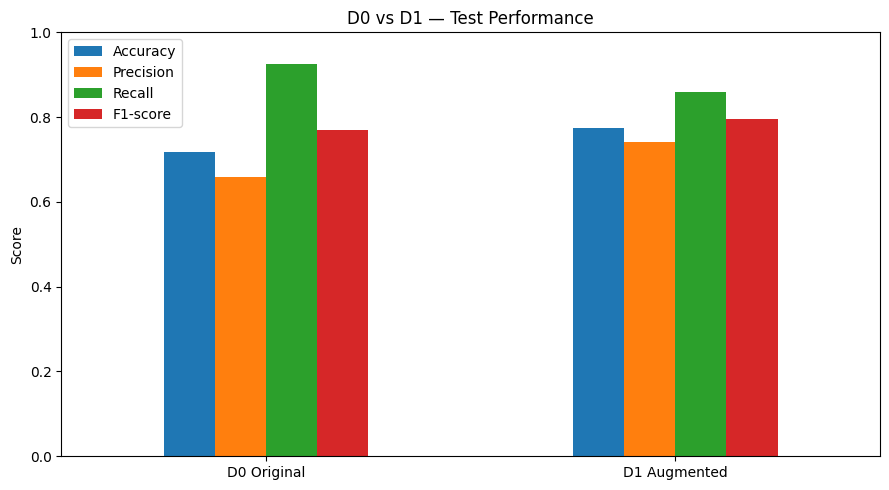

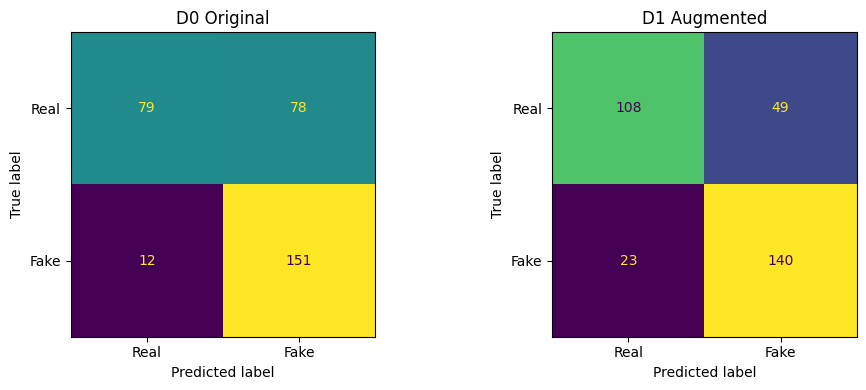

In [8]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

def test_model(model, loader):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(1).cpu().tolist()

            y_true.extend(labels.tolist())
            y_pred.extend(predictions)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }, y_true, y_pred

results_d0, true_d0, pred_d0 = test_model(model_d0, test_loader)
results_d1, true_d1, pred_d1 = test_model(model_d1, test_loader)

results = pd.DataFrame({
    "D0 Original": results_d0,
    "D1 Augmented": results_d1
})

print("FINAL TEST RESULTS:")
print(results.round(4))

results.to_csv("comparison_results.csv")

ax = results.T.plot(kind="bar", figsize=(9, 5))
plt.title("D0 vs D1 — Test Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, y_true, y_pred, title in [
    (axes[0], true_d0, pred_d0, "D0 Original"),
    (axes[1], true_d1, pred_d1, "D1 Augmented")
]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Real", "Fake"]
    ).plot(ax=ax, colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()


FINAL TEST RESULTS:
           D0 Original  D1 Augmented
Accuracy        0.7188        0.7750
Precision       0.6594        0.7407
Recall          0.9264        0.8589
F1-score        0.7704        0.7955


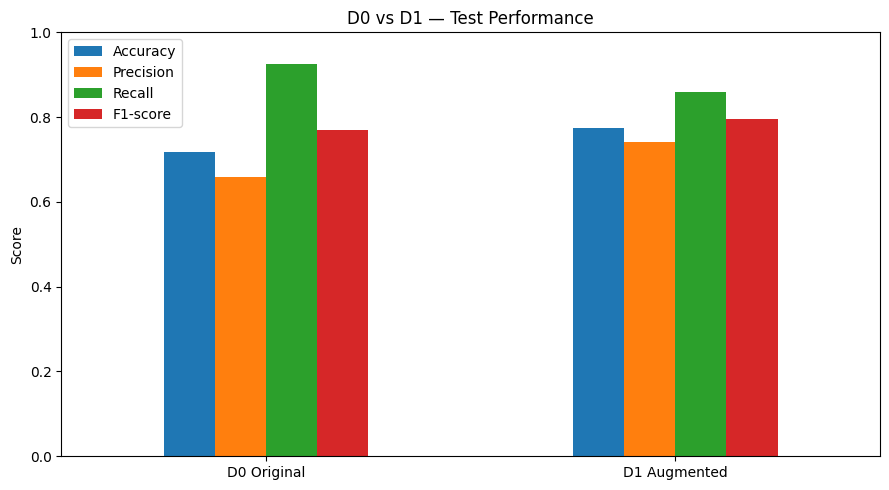

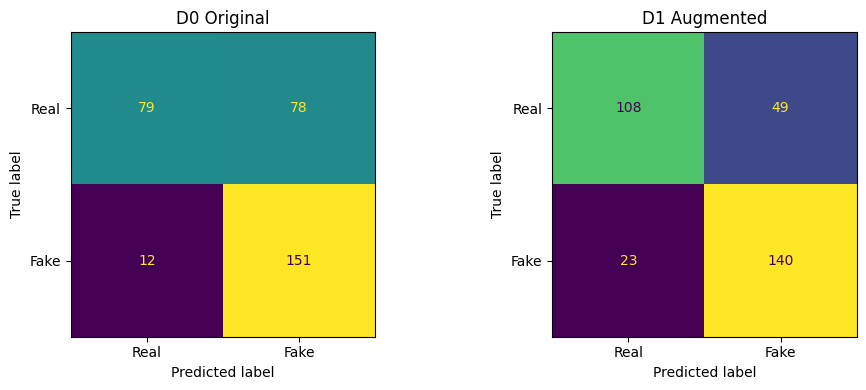

In [9]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

def test_model(model, loader):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(1).cpu().tolist()

            y_true.extend(labels.tolist())
            y_pred.extend(predictions)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }, y_true, y_pred

results_d0, true_d0, pred_d0 = test_model(model_d0, test_loader)
results_d1, true_d1, pred_d1 = test_model(model_d1, test_loader)

results = pd.DataFrame({
    "D0 Original": results_d0,
    "D1 Augmented": results_d1
})

print("FINAL TEST RESULTS:")
print(results.round(4))

results.to_csv("comparison_results.csv")

ax = results.T.plot(kind="bar", figsize=(9, 5))
plt.title("D0 vs D1 — Test Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, y_true, y_pred, title in [
    (axes[0], true_d0, pred_d0, "D0 Original"),
    (axes[1], true_d1, pred_d1, "D1 Augmented")
]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Real", "Fake"]
    ).plot(ax=ax, colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()


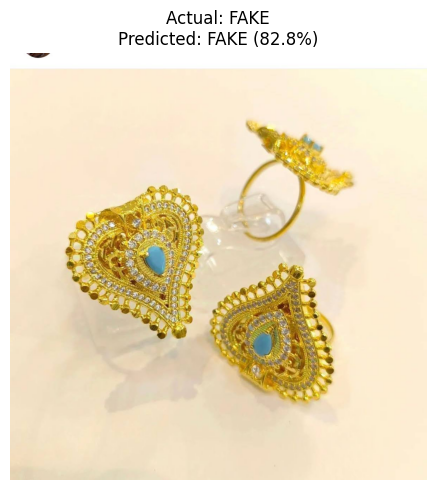

In [10]:
import random
from PIL import Image
import torch
import matplotlib.pyplot as plt

model_d1.eval()

index = random.randrange(len(test_paths))
image_path = test_paths[index]
true_label = test_labels[index]

image = Image.open(image_path).convert("RGB")
input_tensor = normal_transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    output = model_d1(input_tensor)
    probabilities = torch.softmax(output, dim=1)[0]
    prediction = output.argmax(1).item()

predicted_label = "FAKE" if prediction == 1 else "REAL"
confidence = probabilities[prediction].item() * 100

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Actual: {true_label.upper()}\n"
    f"Predicted: {predicted_label} ({confidence:.1f}%)"
)
plt.tight_layout()
plt.savefig("prediction_example.png")
plt.show()


In [11]:
import hashlib

def image_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

train_hashes = {image_hash(p) for p in train_paths}
val_hashes = {image_hash(p) for p in val_paths}
test_hashes = {image_hash(p) for p in test_paths}

print("Train / Validation duplicates:",
      len(train_hashes & val_hashes))

print("Train / Test duplicates:",
      len(train_hashes & test_hashes))

print("Validation / Test duplicates:",
      len(val_hashes & test_hashes))


Train / Validation duplicates: 25
Train / Test duplicates: 17
Validation / Test duplicates: 5


In [12]:

from sklearn.model_selection import train_test_split

unique_images = {}

for path, label in data:
    h = image_hash(path)

    if h not in unique_images:
        unique_images[h] = (path, label)
    elif unique_images[h][1] != label:
        raise ValueError(
            "Same image has conflicting REAL/FAKE labels!"
        )

clean_data = list(unique_images.values())

paths = [p for p, label in clean_data]
labels = [label for p, label in clean_data]

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths, labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Original images:", len(data))
print("Unique images:", len(clean_data))
print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))

train_hashes = {image_hash(p) for p in train_paths}
val_hashes = {image_hash(p) for p in val_paths}
test_hashes = {image_hash(p) for p in test_paths}

print("Train / Validation:", len(train_hashes & val_hashes))
print("Train / Test:", len(train_hashes & test_hashes))
print("Validation / Test:", len(val_hashes & test_hashes))


Original images: 2127
Unique images: 2011
Train: 1407
Validation: 302
Test: 302
Train / Validation: 0
Train / Test: 0
Validation / Test: 0


In [13]:

# Create datasets using cleaned data

train_d0 = GoldDataset(
    train_paths, train_labels, normal_transform
)

train_d1 = GoldDataset(
    train_paths, train_labels, augmented_transform
)

val_dataset = GoldDataset(
    val_paths, val_labels, normal_transform
)

test_dataset = GoldDataset(
    test_paths, test_labels, normal_transform
)

# Create new data loaders

train_loader_d0 = DataLoader(
    train_d0, batch_size=32, shuffle=True
)

train_loader_d1 = DataLoader(
    train_d1, batch_size=32, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False
)

print("Clean datasets ready!")
print("Train:", len(train_d0))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Clean datasets ready!
Train: 1407
Validation: 302
Test: 302


In [14]:
print("Retraining D0...")
model_d0 = train_model(train_loader_d0, epochs=5)
torch.save(model_d0.state_dict(), "model_d0_clean.pth")

print("\nRetraining D1...")
model_d1 = train_model(train_loader_d1, epochs=5)
torch.save(model_d1.state_dict(), "model_d1_clean.pth")

print("\nBoth models retrained successfully!")


Retraining D0...
Epoch 1/5 | Loss: 0.6489 | Val F1: 0.7722
Epoch 2/5 | Loss: 0.5337 | Val F1: 0.7770
Epoch 3/5 | Loss: 0.4820 | Val F1: 0.8065
Epoch 4/5 | Loss: 0.4517 | Val F1: 0.8150
Epoch 5/5 | Loss: 0.4343 | Val F1: 0.7333

Retraining D1...
Epoch 1/5 | Loss: 0.6529 | Val F1: 0.7549
Epoch 2/5 | Loss: 0.5582 | Val F1: 0.7595
Epoch 3/5 | Loss: 0.5335 | Val F1: 0.7871
Epoch 4/5 | Loss: 0.4963 | Val F1: 0.7673
Epoch 5/5 | Loss: 0.4864 | Val F1: 0.7767

Both models retrained successfully!


CLEAN DATASET — FINAL TEST RESULTS
           D0 Original  D1 Augmented
Accuracy        0.8079        0.7649
Precision       0.7818        0.7410
Recall          0.8543        0.8146
F1-score        0.8165        0.7760


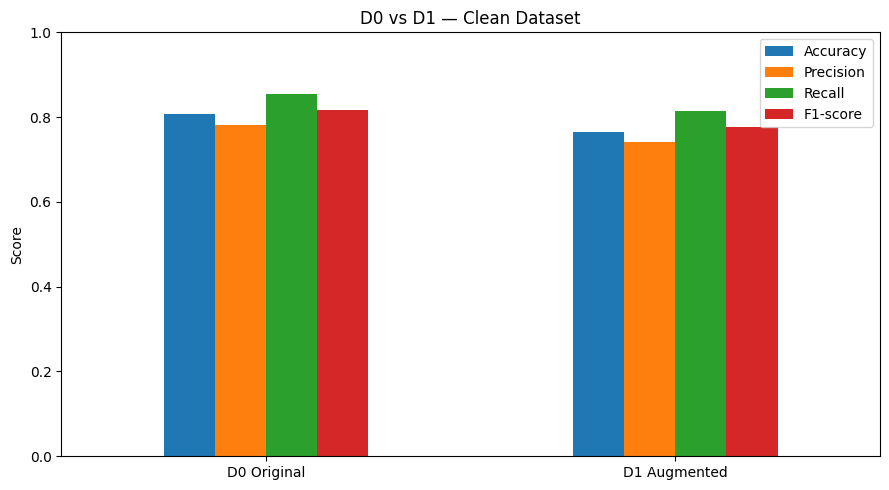

In [15]:

results_d0, true_d0, pred_d0 = test_model(
    model_d0, test_loader
)

results_d1, true_d1, pred_d1 = test_model(
    model_d1, test_loader
)

results = pd.DataFrame({
    "D0 Original": results_d0,
    "D1 Augmented": results_d1
})

print("CLEAN DATASET — FINAL TEST RESULTS")
print(results.round(4))

results.to_csv("comparison_results_clean.csv")

ax = results.T.plot(kind="bar", figsize=(9, 5))
plt.title("D0 vs D1 — Clean Dataset")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_comparison_clean.png")
plt.show()
